# ***DECISION TREE CLASSIFIER - CURRENT Pred***

In [ ]:
#IMPORT ALL THE LIBRARIES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

import warnings
warnings.filterwarnings("ignore")

In [ ]:
#LOAD THE DATASET
df = pd.read_csv("/content/master_network_dataset.csv")

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (4993, 22)


,measurement_id,timestamp,timestamp_original,timestamp_precision,date,time,collector_id,location,source_file,ssid,...,latency_ms,packet_loss_percent,jitter_ms,download_mbps,upload_mbps,wifi_signal_percent,dns_response_ms,http_response_ms,target_reachable,stability
0,G_Block_0001,2026-09-22 11:57:00,9/22/2026 11:57,minute,2026-09-22,11:57:00,yash,G_Block,network_data_yash_G_Block.csv,MR-Campus,...,4.2,0.0,1.50,72.55,11.23,90,1101.06,493.42,1,Stable
1,G_Block_0002,2026-09-22 11:58:00,9/22/2026 11:58,minute,2026-09-22,11:58:00,yash,G_Block,network_data_yash_G_Block.csv,MR-Campus,...,15.6,0.0,11.00,103.35,9.50,79,0.87,586.39,1,Stable
2,G_Block_0003,2026-09-22 11:58:00,9/22/2026 11:58,minute,2026-09-22,11:58:00,yash,G_Block,network_data_yash_G_Block.csv,MR-Campus,...,58.8,0.0,61.50,90.25,12.00,79,0.93,497.76,1,Unstable
3,G_Block_0004,2026-09-22 12:16:00,9/22/2026 12:16,minute,2026-09-22,12:16:00,yash,G_Block,network_data_yash_G_Block.csv,MR-Campus,...,10.2,0.0,3.25,163.84,90.78,93,7155.06,613.17,1,Stable
4,G_Block_0005,2026-09-22 12:16:00,9/22/2026 12:16,minute,2026-09-22,12:16:00,yash,G_Block,network_data_yash_G_Block.csv,MR-Campus,...,43.8,0.0,35.75,195.20,71.64,72,0.60,476.86,1,Unstable


In [ ]:
#CONVERT TIMESTAMP
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce",
    format="mixed"
)

print("First timestamp:", df["timestamp"].min())
print("Last timestamp :", df["timestamp"].max())

print("\nReadings per day:")
print(
    df["timestamp"]
    .dt.date
    .value_counts()
    .sort_index()
)

First timestamp: 2026-09-22 11:57:00
Last timestamp : 2026-09-24 16:17:00

Readings per day:
timestamp
2026-09-22    1497
2026-09-23    2102
2026-09-24    1394
Name: count, dtype: int64


In [ ]:
#SELECT FEATURES AND TARGETS
features = [
    "latency_ms",
    "packet_loss_percent",
    "jitter_ms",
    "download_mbps",
    "upload_mbps",
    "wifi_signal_percent",
    "dns_response_ms",
    "http_response_ms",
    "target_reachable"
]

target = "stability"

print("Features:")
for feature in features:
    print("-", feature)

print("\nTarget:", target)

Features:
- latency_ms
- packet_loss_percent
- jitter_ms
- download_mbps
- upload_mbps
- wifi_signal_percent
- dns_response_ms
- http_response_ms
- target_reachable

Target: stability


In [ ]:
# TRAIN-TEST SPLIT
day1 = pd.Timestamp("2026-09-22").date()
day2 = pd.Timestamp("2026-09-23").date()
day3 = pd.Timestamp("2026-09-24").date()

train_df = df[
    df["timestamp"].dt.date.isin([
        day1,
        day2
    ])
].copy()

test_df = df[
    df["timestamp"].dt.date == day3
].copy()

print("Training rows:", len(train_df))
print("Testing rows :", len(test_df))

Training rows: 3599
Testing rows : 1394


In [ ]:
# VERIFICATION
print("\nTraining dates:")
print(
    train_df["timestamp"]
    .dt.date
    .value_counts()
    .sort_index()
)

print("\nTesting dates:")
print(
    test_df["timestamp"]
    .dt.date
    .value_counts()
    .sort_index()
)


Training dates:
timestamp
2026-09-22    1497
2026-09-23    2102
Name: count, dtype: int64

Testing dates:
timestamp
2026-09-24    1394
Name: count, dtype: int64


In [ ]:
# CREATE X and y
X_train = train_df[features].copy()
y_train = train_df[target].copy()

X_test = test_df[features].copy()
y_test = test_df[target].copy()

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

X_train: (3599, 9)
X_test : (1394, 9)

Training class distribution:
stability
Stable      3095
Unstable     326
Warning      178
Name: count, dtype: int64

Testing class distribution:
stability
Stable      1144
Unstable     180
Warning       70
Name: count, dtype: int64


In [ ]:
# Handle numeric conversion and missing values
for column in features:
    X_train[column] = pd.to_numeric(
        X_train[column],
        errors="coerce"
    )

    X_test[column] = pd.to_numeric(
        X_test[column],
        errors="coerce"
    )
train_medians = X_train.median()

X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)

print(
    "Missing values in training:",
    X_train.isnull().sum().sum()
)

print(
    "Missing values in testing:",
    X_test.isnull().sum().sum()
)

Missing values in training: 0
Missing values in testing: 0


In [ ]:
#TRAIN DECISION TREE
decision_tree = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

decision_tree.fit(
    X_train,
    y_train
)

DecisionTreeClassifier(class_weight='balanced', max_depth=5,
                       min_samples_leaf=10, random_state=42)

In [ ]:
#MAKE PREDICTIONS
train_predictions = decision_tree.predict(
    X_train
)

test_predictions = decision_tree.predict(
    X_test
)

In [ ]:
# Check overfitting
train_accuracy = accuracy_score(
    y_train,
    train_predictions
)

test_accuracy = accuracy_score(
    y_test,
    test_predictions
)

difference = train_accuracy - test_accuracy

print("Decision Tree")
print("------------------------------")

print(
    "Training Accuracy :",
    round(train_accuracy * 100, 2),
    "%"
)

print(
    "Day 3 Accuracy    :",
    round(test_accuracy * 100, 2),
    "%"
)

print(
    "Difference        :",
    round(difference * 100, 2),
    "%"
)

Decision Tree
------------------------------
Training Accuracy : 99.58 %
Day 3 Accuracy    : 99.43 %
Difference        : 0.16 %


In [ ]:
# CALCULATE ALL EVALUATION METRICS
dt_balanced_accuracy = balanced_accuracy_score(
    y_test,
    test_predictions
)

dt_precision = precision_score(
    y_test,
    test_predictions,
    average="macro",
    zero_division=0
)

dt_recall = recall_score(
    y_test,
    test_predictions,
    average="macro",
    zero_division=0
)

dt_f1 = f1_score(
    y_test,
    test_predictions,
    average="macro",
    zero_division=0
)

print("Decision Tree - Day 3 Results")
print("--------------------------------")

print(
    "Accuracy:",
    round(test_accuracy, 4)
)

print(
    "Balanced Accuracy:",
    round(dt_balanced_accuracy, 4)
)

print(
    "Macro Precision:",
    round(dt_precision, 4)
)

print(
    "Macro Recall:",
    round(dt_recall, 4)
)

print(
    "Macro F1:",
    round(dt_f1, 4)
)

Decision Tree - Day 3 Results
--------------------------------
Accuracy: 0.9943
Balanced Accuracy: 0.9899
Macro Precision: 0.9658
Macro Recall: 0.9899
Macro F1: 0.9768


In [ ]:
# CLASSIFICATION REPORT
print(
    classification_report(
        y_test,
        test_predictions,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Stable       1.00      1.00      1.00      1144
    Unstable       1.00      0.97      0.99       180
     Warning       0.90      1.00      0.95        70

    accuracy                           0.99      1394
   macro avg       0.97      0.99      0.98      1394
weighted avg       0.99      0.99      0.99      1394



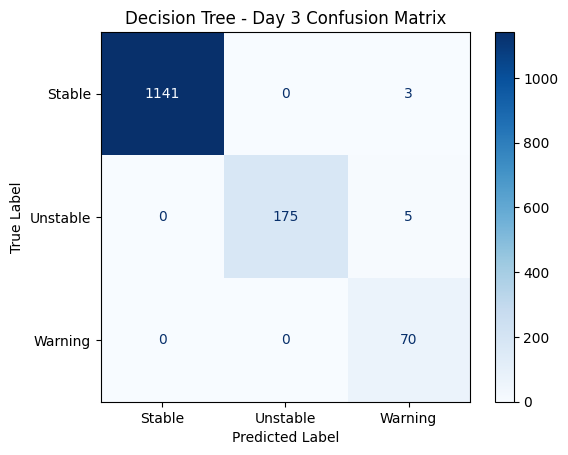

In [ ]:
# CONFUSION MATRIX
ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_predictions,
    cmap="Blues"
)

plt.title(
    "Decision Tree - Day 3 Confusion Matrix"
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

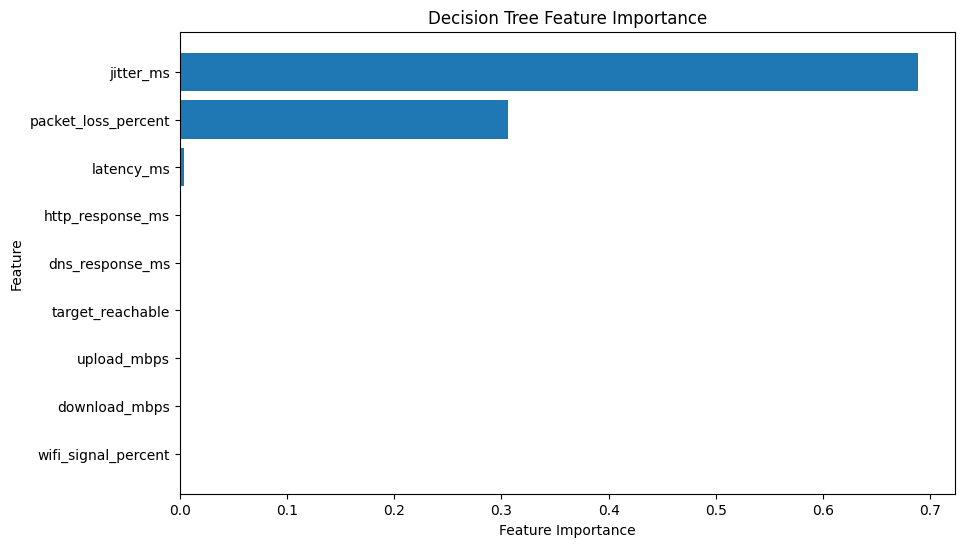

In [ ]:
# FEATURE IMPORTANCE
importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": decision_tree.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

importance_df
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.title(
    "Decision Tree Feature Importance"
)

plt.gca().invert_yaxis()

plt.show()

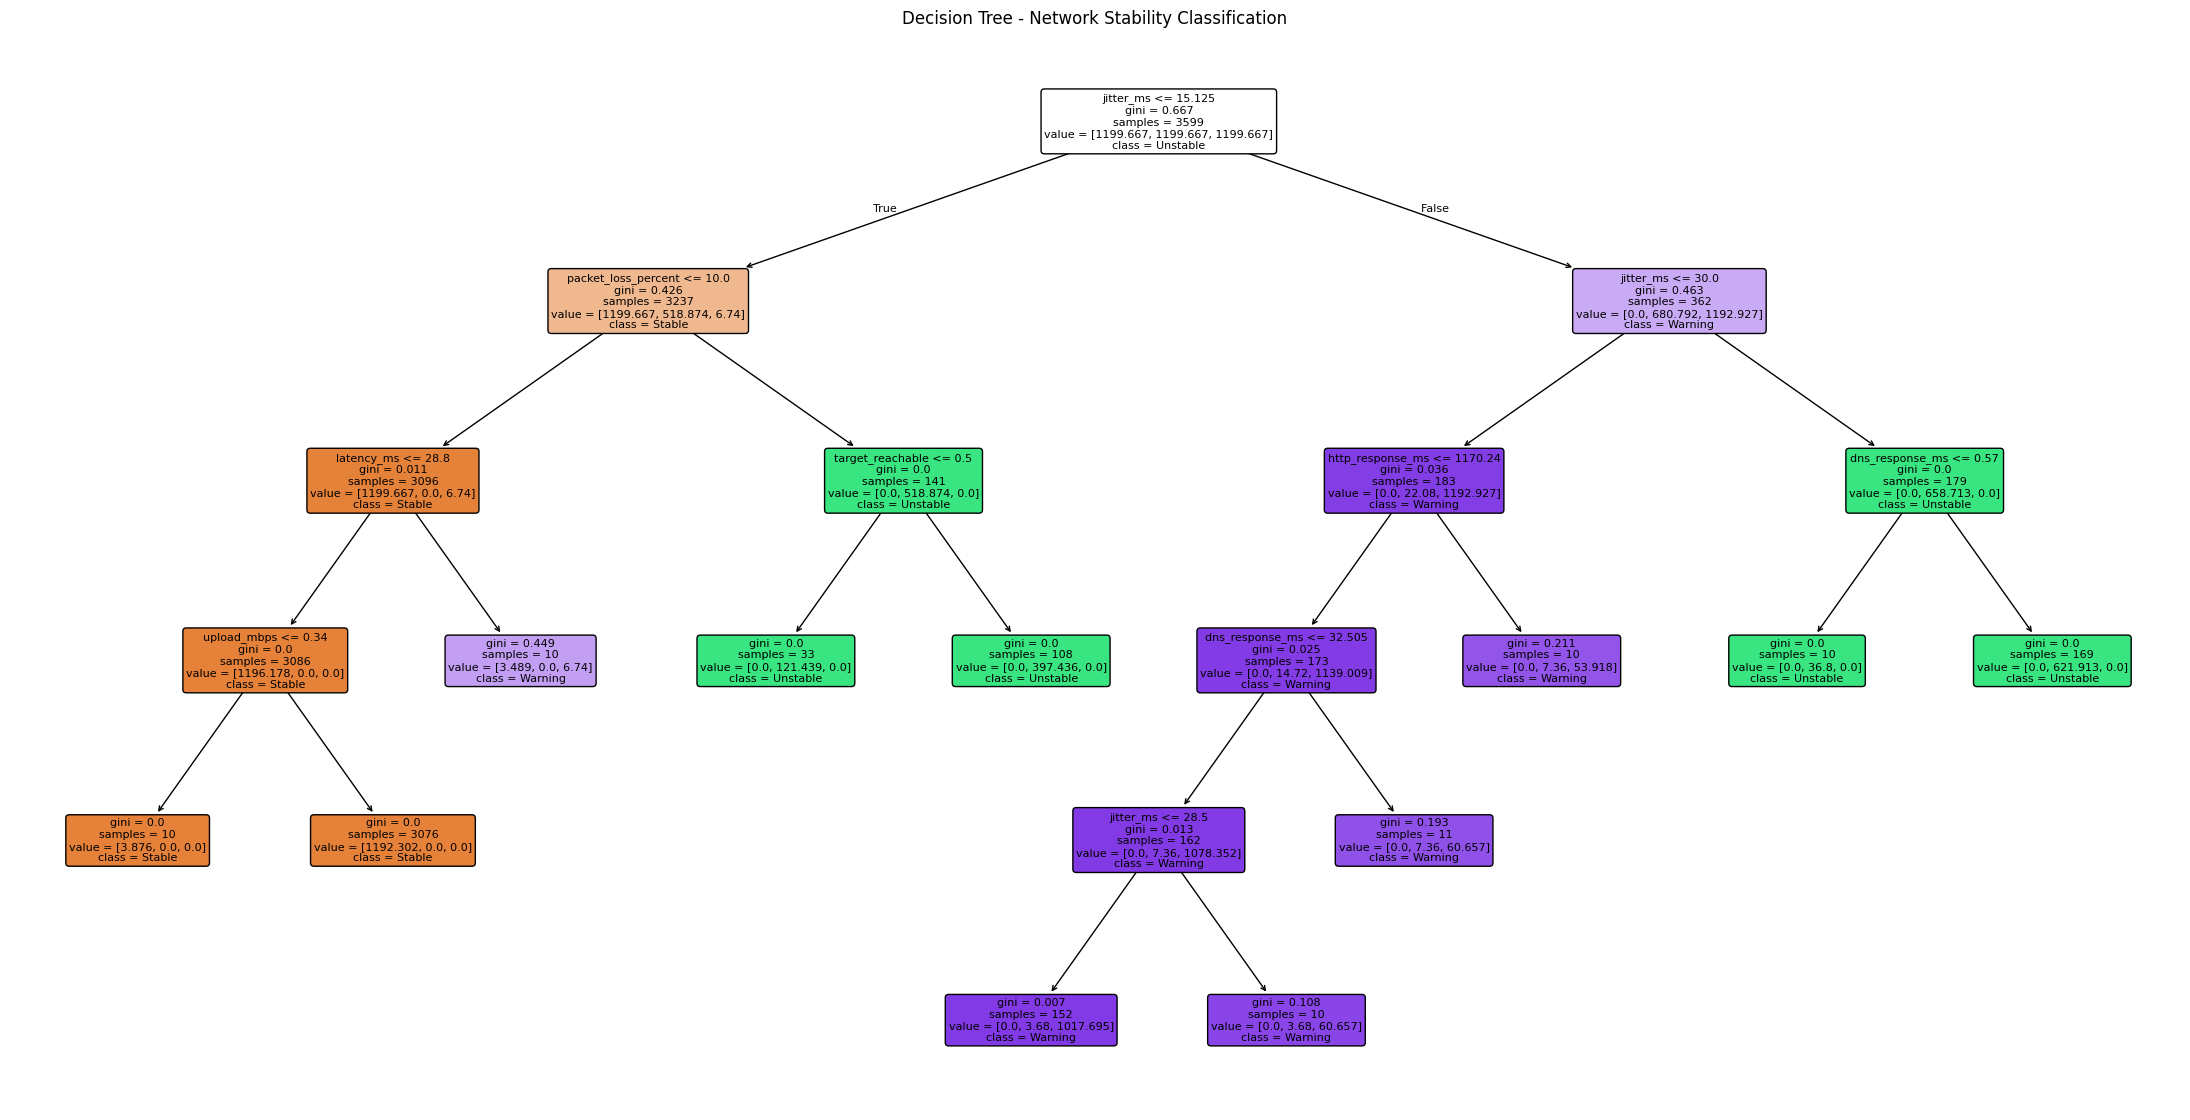

In [ ]:
#VISUALIZE DECISION TREE
plt.figure(figsize=(28, 14))

plot_tree(
    decision_tree,
    feature_names=features,
    class_names=decision_tree.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title(
    "Decision Tree - Network Stability Classification"
)

plt.show()

In [ ]:
# FINAL RESULT SUMMARY
dt_results = pd.DataFrame({
    "Model": ["Decision Tree"],
    "Training Setup": [
        "Day 1 + Day 2 -> Day 3"
    ],
    "Training Accuracy": [
        train_accuracy
    ],
    "Testing Accuracy": [
        test_accuracy
    ],
    "Balanced Accuracy": [
        dt_balanced_accuracy
    ],
    "Macro Precision": [
        dt_precision
    ],
    "Macro Recall": [
        dt_recall
    ],
    "Macro F1": [
        dt_f1
    ]
})

dt_results

,Model,Training Setup,Training Accuracy,Testing Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1
0,Decision Tree,Day 1 + Day 2 -> Day 3,0.995832,0.994261,0.989867,0.965812,0.989867,0.97685


# ***RANDOM FOREST CLASSIFIER - CURRENT Pred***

In [ ]:
# Import Random Forest and metrics
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
# Define the same features and target
features = [
    "latency_ms",
    "packet_loss_percent",
    "jitter_ms",
    "download_mbps",
    "upload_mbps",
    "wifi_signal_percent",
    "dns_response_ms",
    "http_response_ms",
    "target_reachable"
]

target = "stability"

In [ ]:
#CONVERT TIMESTAMP
df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce",
    format="mixed"
)
print("Available dates:")
print("\nReadings per day:")
print(
    df["timestamp"]
    .dt.date
    .value_counts()
    .sort_index()
)

Available dates:

Readings per day:
timestamp
2026-09-22    1497
2026-09-23    2102
2026-09-24    1394
Name: count, dtype: int64


In [ ]:
# Day 1 + Day 2 training, Day 3 testing
day1 = pd.Timestamp("2026-09-22").date()
day2 = pd.Timestamp("2026-09-23").date()
day3 = pd.Timestamp("2026-09-24").date()

train_df_rf = df[
    df["timestamp"].dt.date.isin([
        day1,
        day2
    ])
].copy()

test_df_rf = df[
    df["timestamp"].dt.date == day3
].copy()

print("Training rows:", len(train_df_rf))
print("Testing rows :", len(test_df_rf))
print("\nTraining dates:")

print(
    train_df_rf["timestamp"]
    .dt.date
    .value_counts()
    .sort_index()
)

print("\nTesting dates:")

print(
    test_df_rf["timestamp"]
    .dt.date
    .value_counts()
    .sort_index()
)

Training rows: 3599
Testing rows : 1394

Training dates:
timestamp
2026-09-22    1497
2026-09-23    2102
Name: count, dtype: int64

Testing dates:
timestamp
2026-09-24    1394
Name: count, dtype: int64


In [ ]:
# Create training and testing variables
X_train_rf = train_df_rf[features].copy()
y_train_rf = train_df_rf[target].copy()

X_test_rf = test_df_rf[features].copy()
y_test_rf = test_df_rf[target].copy()

print("Training shape:", X_train_rf.shape)
print("Testing shape :", X_test_rf.shape)

print("\nTraining class distribution:")
print(y_train_rf.value_counts())

print("\nTesting class distribution:")
print(y_test_rf.value_counts())

Training shape: (3599, 9)
Testing shape : (1394, 9)

Training class distribution:
stability
Stable      3095
Unstable     326
Warning      178
Name: count, dtype: int64

Testing class distribution:
stability
Stable      1144
Unstable     180
Warning       70
Name: count, dtype: int64


In [ ]:
# Convert features to numeric
for column in features:

    X_train_rf[column] = pd.to_numeric(
        X_train_rf[column],
        errors="coerce"
    )

    X_test_rf[column] = pd.to_numeric(
        X_test_rf[column],
        errors="coerce"
    )

In [ ]:
# Handle missing values properly. Calculate medians from training data only.
rf_train_medians = X_train_rf.median()

X_train_rf = X_train_rf.fillna(
    rf_train_medians
)

X_test_rf = X_test_rf.fillna(
    rf_train_medians
)

print(
    "Missing values in training:",
    X_train_rf.isnull().sum().sum()
)

print(
    "Missing values in testing:",
    X_test_rf.isnull().sum().sum()
)

Missing values in training: 0
Missing values in testing: 0


In [ ]:
# Create Random Forest model
random_forest = RandomForestClassifier(
    n_estimators=300, # 300 decision trees
    min_samples_leaf=2, # avoids extremely tiny leaf nodes
    class_weight="balanced_subsample", # helps with Stable / Warning / Unstable imbalance
    random_state=42,# reproducible result
    n_jobs=-1 # uses all available CPU cores
)

print(random_forest)

RandomForestClassifier(class_weight='balanced_subsample', min_samples_leaf=2,
                       n_estimators=300, n_jobs=-1, random_state=42)


In [ ]:
# Train Random Forest
random_forest.fit(
    X_train_rf,
    y_train_rf
)

RandomForestClassifier(class_weight='balanced_subsample', min_samples_leaf=2,
                       n_estimators=300, n_jobs=-1, random_state=42)

In [ ]:
# Predictions
rf_train_predictions = random_forest.predict(
    X_train_rf
)

rf_test_predictions = random_forest.predict(
    X_test_rf
)

In [ ]:
# Training vs testing accuracy. This lets us check for overfitting.
rf_train_accuracy = accuracy_score(
    y_train_rf,
    rf_train_predictions
)

rf_test_accuracy = accuracy_score(
    y_test_rf,
    rf_test_predictions
)

rf_difference = (
    rf_train_accuracy -
    rf_test_accuracy
)

print("Random Forest")
print("------------------------------")

print(
    "Training Accuracy :",
    round(rf_train_accuracy * 100, 2),
    "%"
)

print(
    "Day 3 Accuracy    :",
    round(rf_test_accuracy * 100, 2),
    "%"
)

print(
    "Difference        :",
    round(rf_difference * 100, 2),
    "%"
)

Random Forest
------------------------------
Training Accuracy : 100.0 %
Day 3 Accuracy    : 100.0 %
Difference        : 0.0 %


In [ ]:
# Random Forest evaluation metrics
rf_balanced_accuracy = balanced_accuracy_score(
    y_test_rf,
    rf_test_predictions
)

rf_precision = precision_score(
    y_test_rf,
    rf_test_predictions,
    average="macro",
    zero_division=0
)

rf_recall = recall_score(
    y_test_rf,
    rf_test_predictions,
    average="macro",
    zero_division=0
)

rf_f1 = f1_score(
    y_test_rf,
    rf_test_predictions,
    average="macro",
    zero_division=0
)

print("Random Forest - Day 3 Results")
print("--------------------------------")

print(
    "Accuracy:",
    round(rf_test_accuracy, 4)
)

print(
    "Balanced Accuracy:",
    round(rf_balanced_accuracy, 4)
)

print(
    "Macro Precision:",
    round(rf_precision, 4)
)

print(
    "Macro Recall:",
    round(rf_recall, 4)
)

print(
    "Macro F1:",
    round(rf_f1, 4)
)

Random Forest - Day 3 Results
--------------------------------
Accuracy: 1.0
Balanced Accuracy: 1.0
Macro Precision: 1.0
Macro Recall: 1.0
Macro F1: 1.0


In [ ]:
# Classification report
print(
    classification_report(
        y_test_rf,
        rf_test_predictions,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Stable       1.00      1.00      1.00      1144
    Unstable       1.00      1.00      1.00       180
     Warning       1.00      1.00      1.00        70

    accuracy                           1.00      1394
   macro avg       1.00      1.00      1.00      1394
weighted avg       1.00      1.00      1.00      1394



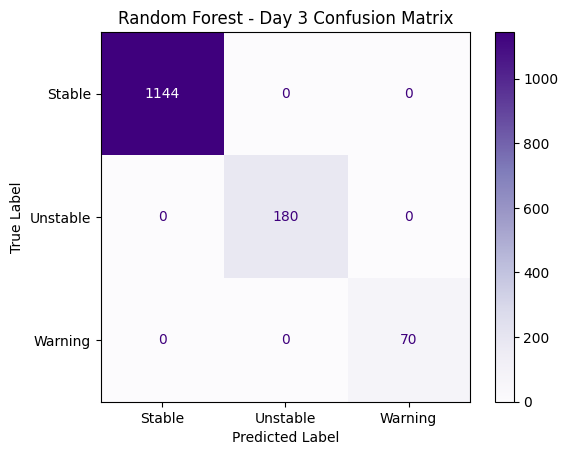

In [ ]:
# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_rf,
    rf_test_predictions,
    cmap="Purples"
)

plt.title(
    "Random Forest - Day 3 Confusion Matrix"
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.show()

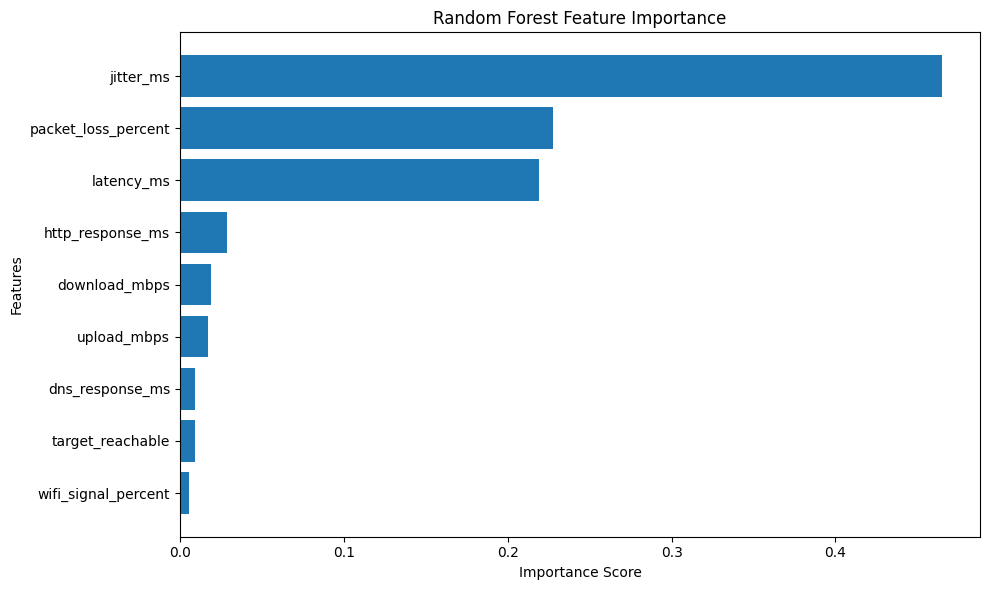

In [ ]:
# Random Forest feature importance
rf_importance_df = pd.DataFrame({
    "Feature": features,
    "Importance": random_forest.feature_importances_
})

rf_importance_df = rf_importance_df.sort_values(
    by="Importance",
    ascending=False
)

rf_importance_df
plt.figure(figsize=(10, 6))

plt.barh(
    rf_importance_df["Feature"],
    rf_importance_df["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()

plt.show()

In [ ]:
# Decision Tree vs Random Forest comparison
comparison = pd.DataFrame({

    "Model": [
        "Decision Tree",
        "Random Forest"
    ],

    "Training Setup": [
        "Day 1 + Day 2 -> Day 3",
        "Day 1 + Day 2 -> Day 3"
    ],

    "Training Accuracy": [
        train_accuracy,
        rf_train_accuracy
    ],

    "Testing Accuracy": [
        test_accuracy,
        rf_test_accuracy
    ],

    "Balanced Accuracy": [
        dt_balanced_accuracy,
        rf_balanced_accuracy
    ],

    "Macro Precision": [
        dt_precision,
        rf_precision
    ],

    "Macro Recall": [
        dt_recall,
        rf_recall
    ],

    "Macro F1": [
        dt_f1,
        rf_f1
    ]
})

comparison

,Model,Training Setup,Training Accuracy,Testing Accuracy,Balanced Accuracy,Macro Precision,Macro Recall,Macro F1
0,Decision Tree,Day 1 + Day 2 -> Day 3,0.995832,0.994261,0.989867,0.965812,0.989867,0.97685
1,Random Forest,Day 1 + Day 2 -> Day 3,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [ ]:
# Compare errors directly
dt_errors = (
    y_test != test_predictions
).sum()

rf_errors = (
    y_test_rf != rf_test_predictions
).sum()

print("Model Error Comparison")
print("---------------------------")

print(
    "Decision Tree errors:",
    dt_errors
)

print(
    "Random Forest errors:",
    rf_errors
)

Model Error Comparison
---------------------------
Decision Tree errors: 8
Random Forest errors: 0


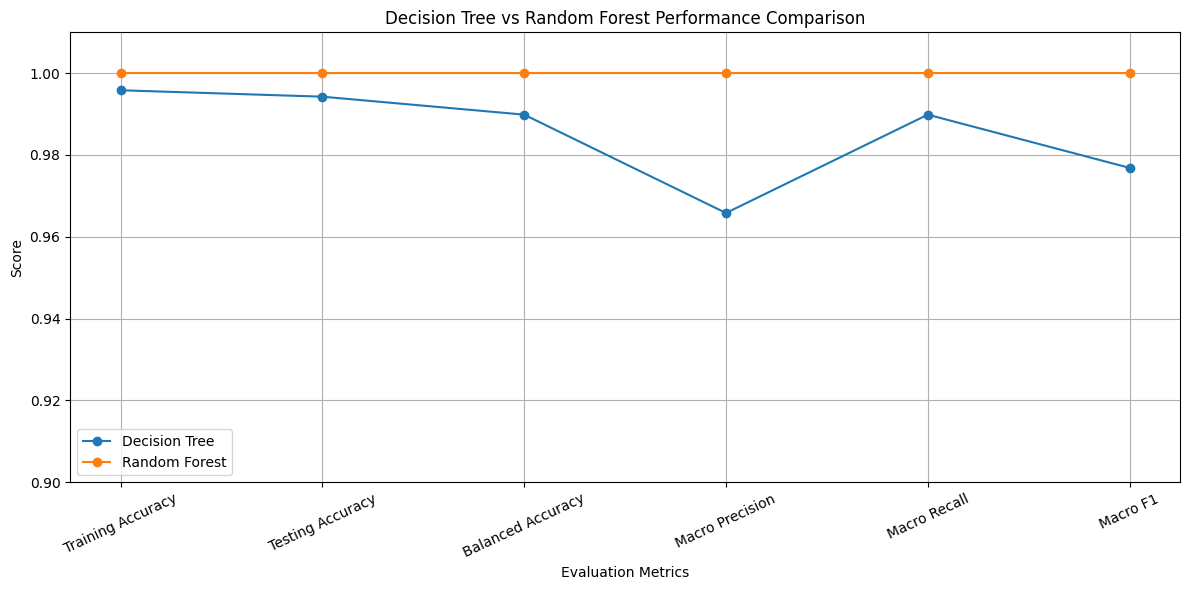

In [ ]:
# Compare Decision Tree vs Random Forest on all evaluation metrics

metrics = [
    "Training Accuracy",
    "Testing Accuracy",
    "Balanced Accuracy",
    "Macro Precision",
    "Macro Recall",
    "Macro F1"
]

decision_tree_scores = [
    train_accuracy,
    test_accuracy,
    dt_balanced_accuracy,
    dt_precision,
    dt_recall,
    dt_f1
]

random_forest_scores = [
    rf_train_accuracy,
    rf_test_accuracy,
    rf_balanced_accuracy,
    rf_precision,
    rf_recall,
    rf_f1
]

plt.figure(figsize=(12, 6))

plt.plot(
    metrics,
    decision_tree_scores,
    marker="o",
    label="Decision Tree"
)

plt.plot(
    metrics,
    random_forest_scores,
    marker="o",
    label="Random Forest"
)

plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("Decision Tree vs Random Forest Performance Comparison")

plt.ylim(0.90, 1.01)

plt.xticks(rotation=25)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# ***True Future Prediction***

In [ ]:
# Create a 5-minute-ahead target
import numpy as np
import pandas as pd

# separate dataframe for prediction work
pred_df = df.copy()

# Ensure timestamp is datetime
pred_df["timestamp"] = pd.to_datetime(
    pred_df["timestamp"],
    errors="coerce",
    format="mixed"
)

# Keep date so targets never cross from one day into another
pred_df["date"] = pred_df["timestamp"].dt.date

# Decide how to separate independent network-monitoring sequences
group_cols = []

if "collector_id" in pred_df.columns:
    group_cols.append("collector_id")

if "location" in pred_df.columns:
    group_cols.append("location")
print("Prediction groups:", group_cols)

Prediction groups: ['collector_id', 'location']


In [ ]:
# Build future_stability_5min
pred_df["future_stability_5min"] = None
pred_df["future_timestamp"] = pd.NaT
pred_df["forecast_gap_seconds"] = np.nan

groups_for_target = group_cols + ["date"]

for _, group in pred_df.groupby(
    groups_for_target,
    dropna=False
):

    group = group.sort_values("timestamp")

    times = group["timestamp"].to_numpy(
        dtype="datetime64[ns]"
    )

    indices = group.index.to_numpy()
    labels = group["stability"].to_numpy()

    for i in range(len(group)):

        current_time = times[i]

        target_time = (
            current_time +
            np.timedelta64(5, "m")
        )

        # Find where 5 minutes later would occur
        pos = np.searchsorted(
            times,
            target_time
        )

        candidates = []

        # Check observation immediately before
        # and immediately after the 5-minute point
        for candidate_pos in [pos - 1, pos]:

            if (
                candidate_pos > i
                and
                candidate_pos < len(times)
            ):

                candidate_time = times[candidate_pos]

                difference_seconds = abs(
                    (
                        candidate_time -
                        target_time
                    ) / np.timedelta64(1, "s")
                )

                # Accept only if near 5 minutes
                if difference_seconds <= 90:

                    candidates.append(
                        (
                            difference_seconds,
                            candidate_pos
                        )
                    )

        if len(candidates) > 0:

            # Choose closest observation to 5 minutes
            candidates.sort(
                key=lambda x: x[0]
            )

            _, best_pos = candidates[0]

            row_index = indices[i]

            pred_df.loc[
                row_index,
                "future_stability_5min"
            ] = labels[best_pos]

            pred_df.loc[
                row_index,
                "future_timestamp"
            ] = pd.Timestamp(
                times[best_pos]
            )

            actual_gap = (
                times[best_pos] -
                current_time
            ) / np.timedelta64(1, "s")

            pred_df.loc[
                row_index,
                "forecast_gap_seconds"
            ] = actual_gap

In [ ]:
# Check how many usable future targets we created
print(
    "Original rows:",
    len(pred_df)
)

print(
    "Rows with 5-minute future target:",
    pred_df["future_stability_5min"]
    .notna()
    .sum()
)

print(
    "\nRows without future target:",
    pred_df["future_stability_5min"]
    .isna()
    .sum()
)

Original rows: 4993
Rows with 5-minute future target: 4886

Rows without future target: 107


In [ ]:
# Inspecting some examples
pred_df[
    [
        "timestamp",
        "future_timestamp",
        "forecast_gap_seconds",
        "stability",
        "future_stability_5min"
    ]
].dropna().head(20)

,timestamp,future_timestamp,forecast_gap_seconds,stability,future_stability_5min
3,2026-09-22 12:16:00,2026-09-22 12:21:00,300.0,Stable,Stable
4,2026-09-22 12:16:00,2026-09-22 12:21:00,300.0,Unstable,Stable
5,2026-09-22 12:16:00,2026-09-22 12:21:00,300.0,Unstable,Stable
6,2026-09-22 12:17:00,2026-09-22 12:22:00,300.0,Stable,Stable
7,2026-09-22 12:17:00,2026-09-22 12:22:00,300.0,Stable,Stable
8,2026-09-22 12:17:00,2026-09-22 12:22:00,300.0,Unstable,Stable
9,2026-09-22 12:17:00,2026-09-22 12:22:00,300.0,Warning,Stable
10,2026-09-22 12:17:35,2026-09-22 12:22:29,294.0,Stable,Stable
11,2026-09-22 12:18:00,2026-09-22 12:23:00,300.0,Stable,Stable
12,2026-09-22 12:18:00,2026-09-22 12:23:00,300.0,Stable,Stable


In [ ]:
# Keep only rows having a future target
future_df = pred_df[
    pred_df["future_stability_5min"].notna()
].copy()

print(
    "Final prediction dataset:",
    future_df.shape
)

Final prediction dataset: (4886, 25)


In [ ]:
# Check future target distribution
print(
    future_df[
        "future_stability_5min"
    ].value_counts()
)

print(
    "\nPercentages:"
)

print(
    future_df[
        "future_stability_5min"
    ]
    .value_counts(normalize=True)
    * 100
)

future_stability_5min
Stable      4137
Unstable     508
Warning      241
Name: count, dtype: int64

Percentages:
future_stability_5min
Stable      84.670487
Unstable    10.397053
Warning      4.932460
Name: proportion, dtype: float64


In [ ]:
# Features for real prediction
prediction_features = [
    "latency_ms",
    "packet_loss_percent",
    "jitter_ms",
    "download_mbps",
    "upload_mbps",
    "wifi_signal_percent",
    "dns_response_ms",
    "http_response_ms",
    "target_reachable"
]

future_target = "future_stability_5min"

In [ ]:
# Day 1 + Day 2 / Day 3 split
day1 = pd.Timestamp("2026-09-22").date()
day2 = pd.Timestamp("2026-09-23").date()
day3 = pd.Timestamp("2026-09-24").date()

future_train_df = future_df[
    future_df["timestamp"]
    .dt.date
    .isin([
        day1,
        day2
    ])
].copy()

future_test_df = future_df[
    future_df["timestamp"]
    .dt.date
    == day3
].copy()

print(
    "Training rows:",
    len(future_train_df)
)

print(
    "Testing rows:",
    len(future_test_df)
)

Training rows: 3516
Testing rows: 1370


In [ ]:
# Create X and y
X_train_future = future_train_df[
    prediction_features
].copy()

y_train_future = future_train_df[
    future_target
].copy()

X_test_future = future_test_df[
    prediction_features
].copy()

y_test_future = future_test_df[
    future_target
].copy()

print(
    "Training:",
    X_train_future.shape
)

print(
    "Testing:",
    X_test_future.shape
)

Training: (3516, 9)
Testing: (1370, 9)


In [ ]:
# Convert features to numeric
for column in prediction_features:

    X_train_future[column] = pd.to_numeric(
        X_train_future[column],
        errors="coerce"
    )

    X_test_future[column] = pd.to_numeric(
        X_test_future[column],
        errors="coerce"
    )

In [ ]:
# Missing values
future_train_medians = (
    X_train_future.median()
)

X_train_future = (
    X_train_future.fillna(
        future_train_medians
    )
)

X_test_future = (
    X_test_future.fillna(
        future_train_medians
    )
)

print(
    "Train missing:",
    X_train_future
    .isnull()
    .sum()
    .sum()
)

print(
    "Test missing:",
    X_test_future
    .isnull()
    .sum()
    .sum()
)

Train missing: 0
Test missing: 0


In [ ]:
# Random Forest — real 5-minute prediction
from sklearn.ensemble import RandomForestClassifier

future_random_forest = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

future_random_forest.fit(
    X_train_future,
    y_train_future
)

RandomForestClassifier(class_weight='balanced_subsample', min_samples_leaf=2,
                       n_estimators=300, n_jobs=-1, random_state=42)

In [ ]:
# Predictions
future_train_predictions = (
    future_random_forest.predict(
        X_train_future
    )
)

future_test_predictions = (
    future_random_forest.predict(
        X_test_future
    )
)

In [ ]:
# Training vs Day 3
from sklearn.metrics import accuracy_score

future_train_accuracy = accuracy_score(
    y_train_future,
    future_train_predictions
)

future_test_accuracy = accuracy_score(
    y_test_future,
    future_test_predictions
)

print(
    "Training Accuracy:",
    round(
        future_train_accuracy * 100,
        2
    ),
    "%"
)

print(
    "Day 3 Accuracy:",
    round(
        future_test_accuracy * 100,
        2
    ),
    "%"
)

print(
    "Difference:",
    round(
        (
            future_train_accuracy -
            future_test_accuracy
        ) * 100,
        2
    ),
    "%"
)

Training Accuracy: 99.72 %
Day 3 Accuracy: 80.88 %
Difference: 18.84 %


In [ ]:
# Full evaluation
from sklearn.metrics import (
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

future_balanced_accuracy = (
    balanced_accuracy_score(
        y_test_future,
        future_test_predictions
    )
)

future_macro_precision = (
    precision_score(
        y_test_future,
        future_test_predictions,
        average="macro",
        zero_division=0
    )
)

future_macro_recall = (
    recall_score(
        y_test_future,
        future_test_predictions,
        average="macro",
        zero_division=0
    )
)

future_macro_f1 = (
    f1_score(
        y_test_future,
        future_test_predictions,
        average="macro",
        zero_division=0
    )
)

print(
    "5-Minute Network Prediction Results"
)

print("--------------------------------")

print(
    "Accuracy:",
    round(future_test_accuracy, 4)
)

print(
    "Balanced Accuracy:",
    round(
        future_balanced_accuracy,
        4
    )
)

print(
    "Macro Precision:",
    round(
        future_macro_precision,
        4
    )
)

print(
    "Macro Recall:",
    round(
        future_macro_recall,
        4
    )
)

print(
    "Macro F1:",
    round(
        future_macro_f1,
        4
    )
)

5-Minute Network Prediction Results
--------------------------------
Accuracy: 0.8088
Balanced Accuracy: 0.3379
Macro Precision: 0.3603
Macro Recall: 0.3379
Macro F1: 0.3144


In [ ]:
# Classification report
print(
    classification_report(
        y_test_future,
        future_test_predictions,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Stable       0.82      0.99      0.89      1118
    Unstable       0.26      0.03      0.05       185
     Warning       0.00      0.00      0.00        67

    accuracy                           0.81      1370
   macro avg       0.36      0.34      0.31      1370
weighted avg       0.70      0.81      0.74      1370



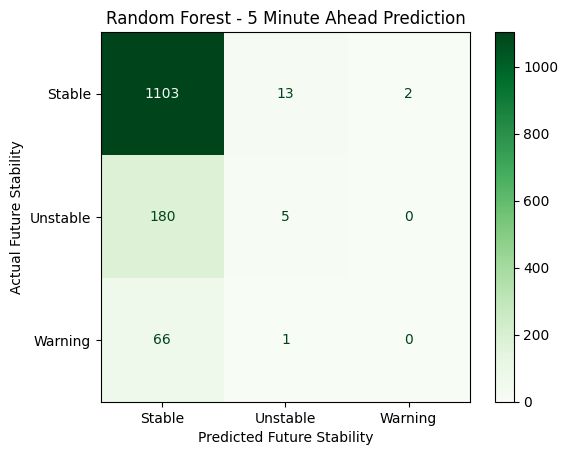

In [ ]:
# Confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test_future,
    future_test_predictions,
    cmap="Greens"
)

plt.title(
    "Random Forest - 5 Minute Ahead Prediction"
)

plt.xlabel(
    "Predicted Future Stability"
)

plt.ylabel(
    "Actual Future Stability"
)

plt.show()


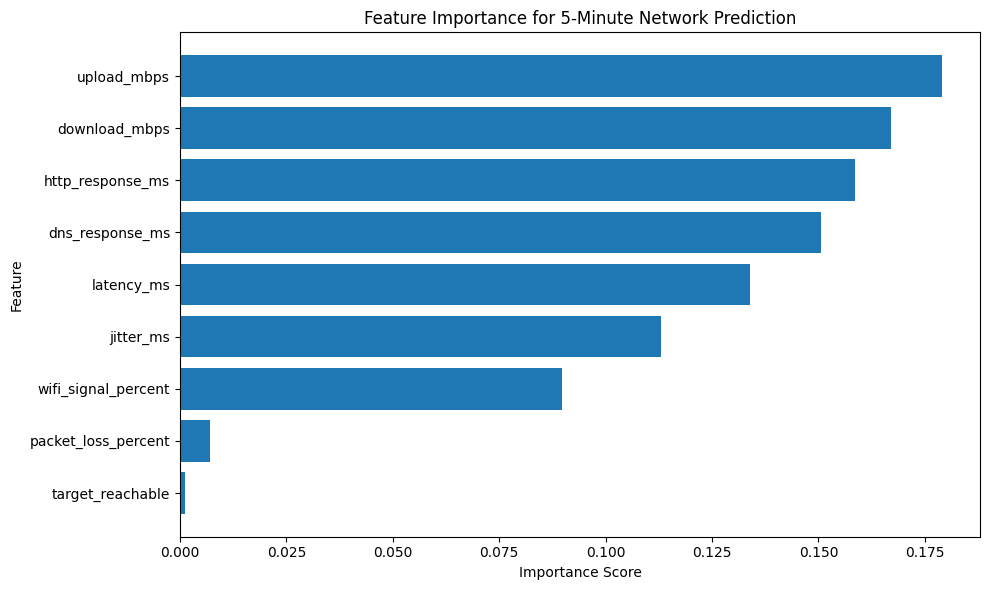

In [ ]:
# Future prediction feature importance
future_importance_df = pd.DataFrame({
    "Feature":
        prediction_features,

    "Importance":
        future_random_forest
        .feature_importances_
})

future_importance_df = (
    future_importance_df
    .sort_values(
        "Importance",
        ascending=False
    )
)

future_importance_df
plt.figure(
    figsize=(10, 6)
)

plt.barh(
    future_importance_df["Feature"],
    future_importance_df["Importance"]
)

plt.xlabel(
    "Importance Score"
)

plt.ylabel(
    "Feature"
)

plt.title(
    "Feature Importance for "
    "5-Minute Network Prediction"
)

plt.gca().invert_yaxis()

plt.tight_layout()

plt.show()